In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('cardekho_dataset.csv')
display(df.describe())
display(df.head())
df.info

,Unnamed: 0,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price
count,15411.000000,15411.000000,1.541100e+04,15411.000000,15411.000000,15411.000000,15411.000000,1.541100e+04
mean,9811.857699,6.036338,5.561648e+04,19.701151,1486.057751,100.588254,5.325482,7.749711e+05
std,5643.418542,3.013291,5.161855e+04,4.171265,521.106696,42.972979,0.807628,8.941284e+05
min,0.000000,0.000000,1.000000e+02,4.000000,793.000000,38.400000,0.000000,4.000000e+04
25%,4906.500000,4.000000,3.000000e+04,17.000000,1197.000000,74.000000,5.000000,3.850000e+05
50%,9872.000000,6.000000,5.000000e+04,19.670000,1248.000000,88.500000,5.000000,5.560000e+05
75%,14668.500000,8.000000,7.000000e+04,22.700000,1582.000000,117.300000,5.000000,8.250000e+05
max,19543.000000,29.000000,3.800000e+06,33.540000,6592.000000,626.000000,9.000000,3.950000e+07


,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


<bound method DataFrame.info of        Unnamed: 0         car_name     brand     model  vehicle_age  \
0               0      Maruti Alto    Maruti      Alto            9   
1               1    Hyundai Grand   Hyundai     Grand            5   
2               2      Hyundai i20   Hyundai       i20           11   
3               3      Maruti Alto    Maruti      Alto            9   
4               4    Ford Ecosport      Ford  Ecosport            6   
...           ...              ...       ...       ...          ...   
15406       19537      Hyundai i10   Hyundai       i10            9   
15407       19540    Maruti Ertiga    Maruti    Ertiga            2   
15408       19541      Skoda Rapid     Skoda     Rapid            6   
15409       19542  Mahindra XUV500  Mahindra    XUV500            5   
15410       19543       Honda City     Honda      City            2   

       km_driven seller_type fuel_type transmission_type  mileage  engine  \
0         120000  Individual    Petrol

In [3]:
# Drop the redundant 'Unnamed: 0' index column if it exists
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

# i had to check for unique values for categorical features to ensure consistency
print("Seller Types:", df['seller_type'].unique())
print("Fuel Types:", df['fuel_type'].unique())
print("Transmission Types:", df['transmission_type'].unique())

# Then Remove extreme km_driven outliers (e.g., anything above 1,000,000 km for a used car is unrealistic)
initial_count = len(df)
df = df[df['km_driven'] <= 1000000]
print(f"\nRemoved {initial_count - len(df)} unrealistic outlier rows based on km_driven.")

Seller Types: ['Individual' 'Dealer' 'Trustmark Dealer']
Fuel Types: ['Petrol' 'Diesel' 'CNG' 'LPG' 'Electric']
Transmission Types: ['Manual' 'Automatic']

Removed 2 unrealistic outlier rows based on km_driven.


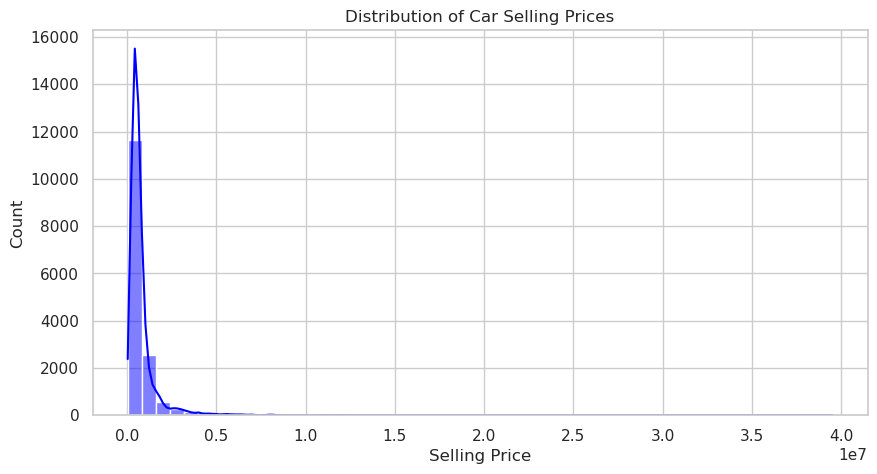

/tmp/ipykernel_900/2027874226.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='fuel_type', y='selling_price', data=df, palette='Set2')


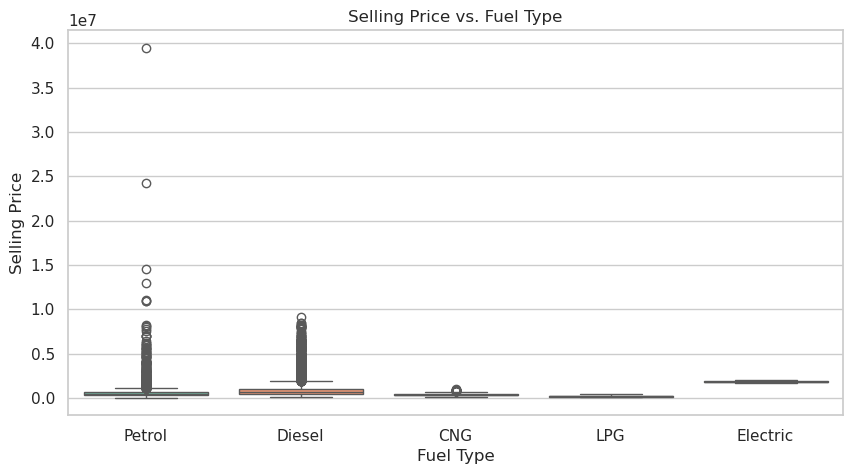

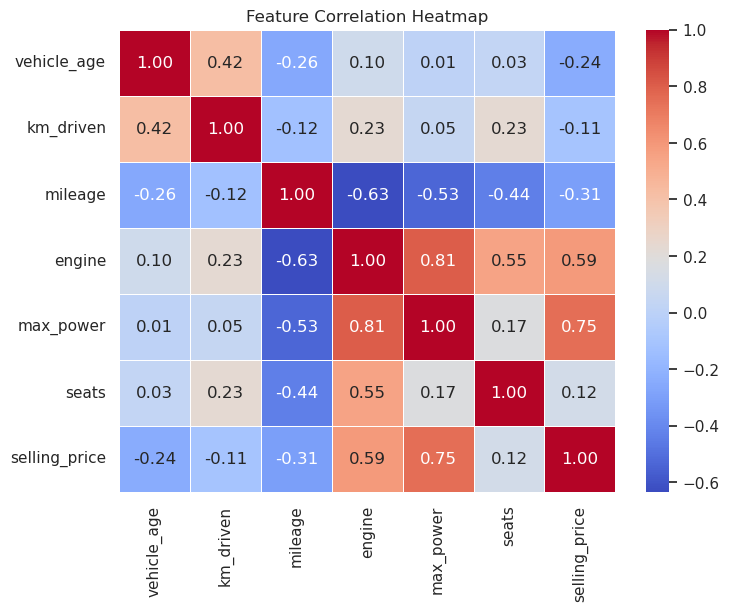

In [4]:
# then also i had to Set the visual style for seaborn
sns.set_theme(style="whitegrid")

# 1. Distribution of Selling Prices
plt.figure(figsize=(10, 5))
sns.histplot(df['selling_price'], kde=True, color='blue', bins=50)
plt.title('Distribution of Car Selling Prices')
plt.xlabel('Selling Price')
plt.ylabel('Count')
plt.show()

# 2. Price vs. Fuel Type (Box Plot)
plt.figure(figsize=(10, 5))
sns.boxplot(x='fuel_type', y='selling_price', data=df, palette='Set2')
plt.title('Selling Price vs. Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Selling Price')
plt.show()

# 3. Correlation Heatmap for Numerical Features
plt.figure(figsize=(8, 6))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.show()

In [5]:
from sklearn.model_selection import train_test_split

# 1. Select the features we want to use for prediction
# We drop unnecessary text columns like 'car_name' and 'model' because they have too many unique variations, 
# and we drop 'selling_price' because that is our target (what we want to predict).
X = df.drop(columns=['car_name', 'model', 'selling_price'])
y = df['selling_price']

# 2. One-Hot Encode categorical columns so machine learning models can read them
X = pd.get_dummies(X, drop_first=True)

print(f"Features shape (X): {X.shape}")
print(f"Target shape (y): {y.shape}")

# 3. Train-Test Split (80% training, 20% testing) to prevent cheating/overfitting
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"\nTraining set rows: {X_train.shape[0]}")
print(f"Testing set rows: {X_test.shape[0]}")

Features shape (X): (15409, 44)
Target shape (y): (15409,)

Training set rows: 12327
Testing set rows: 3082


In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Train Linear Regression (Baseline)
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

# 2. Train Random Forest Regressor (Advanced)
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

# 3. Evaluation Function to print metrics cleanly
def evaluate_model(true_values, predictions, model_name):
    mae = mean_absolute_error(true_values, predictions)
    rmse = np.sqrt(mean_squared_error(true_values, predictions))
    r2 = r2_score(true_values, predictions)
    
    print(f"--- {model_name} PERFORMANCE ---")
    print(f"MAE (Mean Absolute Error): {mae:,.2f}")
    print(f"RMSE (Root Mean Squared Error): {rmse:,.2f}")
    print(f"R2 Score (Accuracy): {r2:.4f}\n")

# Evaluate both models
evaluate_model(y_test, lr_pred, "Linear Regression")
evaluate_model(y_test, rf_pred, "Random Forest Regressor")

--- Linear Regression PERFORMANCE ---
MAE (Mean Absolute Error): 212,123.08
RMSE (Root Mean Squared Error): 427,863.91
R2 Score (Accuracy): 0.7473

--- Random Forest Regressor PERFORMANCE ---
MAE (Mean Absolute Error): 99,796.98
RMSE (Root Mean Squared Error): 211,364.70
R2 Score (Accuracy): 0.9383



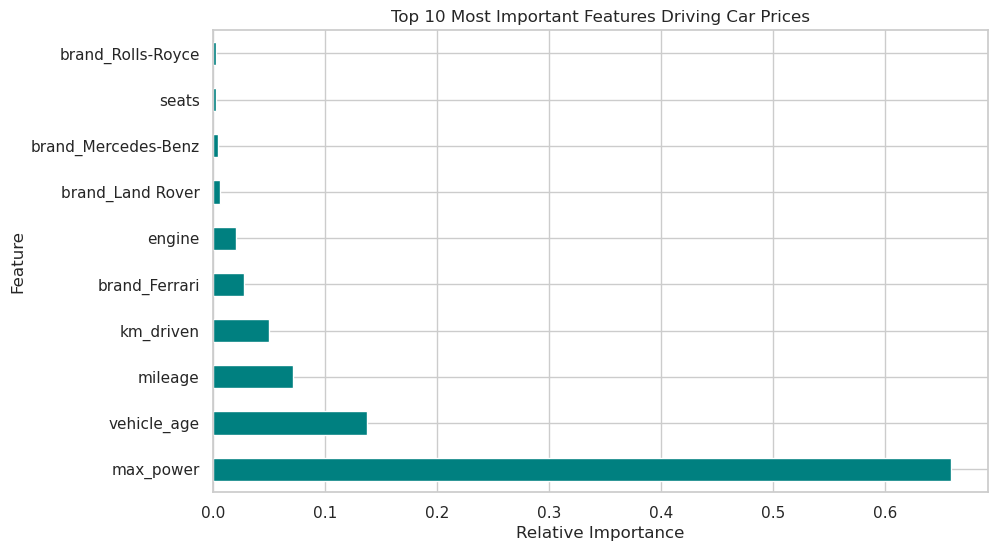

In [7]:
# Feature Importance Plot for Random Forest
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

feature_importances = pd.Series(rf_model.feature_importances_, index=X.columns)
plt.figure(figsize=(10, 6))
feature_importances.nlargest(10).plot(kind='barh', color='teal')
plt.title('Top 10 Most Important Features Driving Car Prices')
plt.xlabel('Relative Importance')
plt.ylabel('Feature')
plt.show()

In [8]:
import pandas as pd
import numpy as np

def predict_custom_car(year, km_driven, mileage, engine, max_power, seats, fuel_type, seller_type, transmission_type):
    # 1. Calculate vehicle age (assuming dataset baseline year is roughly 2024 or max year in df)
    # If your dataset uses a hard 'vehicle_age' column directly, we pass that.
    vehicle_age = 2026 - year 
    
    # 2. Create a blank template matching the exact encoded column structure of X
    input_data = pd.DataFrame(0, index=[0], columns=X.columns)
    
    # 3. Fill in the numerical values
    if 'vehicle_age' in input_data.columns:
        input_data['vehicle_age'] = vehicle_age
    if 'km_driven' in input_data.columns:
        input_data['km_driven'] = km_driven
    if 'mileage' in input_data.columns:
        input_data['mileage'] = mileage
    if 'engine' in input_data.columns:
        input_data['engine'] = engine
    if 'max_power' in input_data.columns:
        input_data['max_power'] = max_power
    if 'seats' in input_data.columns:
        input_data['seats'] = seats

    # 4. Handle the categorical text fields (One-Hot Encoding matching)
    # It sets the appropriate dummy column to 1 (e.g., brand_Mercedes-Benz, fuel_type_Diesel)
    for col in input_data.columns:
        if f"fuel_type_{fuel_type}" in col:
            input_data[col] = 1
        if f"seller_type_{seller_type}" in col:
            input_data[col] = 1
        if f"transmission_type_{transmission_type}" in col:
            input_data[col] = 1
            
    # 5. Make the prediction using your trained Random Forest Model
    predicted_price = rf_model.predict(input_data)[0]
    
    print("--- CUSTOM CAR VALUATION ---")
    print(f"Vehicle Specifications: {year} | {fuel_type} | {transmission_type} | {km_driven:,} km")
    print(f"Estimated Market Value: ₦{predicted_price:,.2f}")

# --- TEST IT OUT HERE ---
# Change these values to test out any car specs you want!
predict_custom_car(
    year=2018, 
    km_driven=50000, 
    mileage=18.5, 
    engine=1200, 
    max_power=85.0, 
    seats=5, 
    fuel_type='Petrol', 
    seller_type='Individual', 
    transmission_type='Manual'
)


--- CUSTOM CAR VALUATION ---
Vehicle Specifications: 2018 | Petrol | Manual | 50,000 km
Estimated Market Value: ₦362,970.00


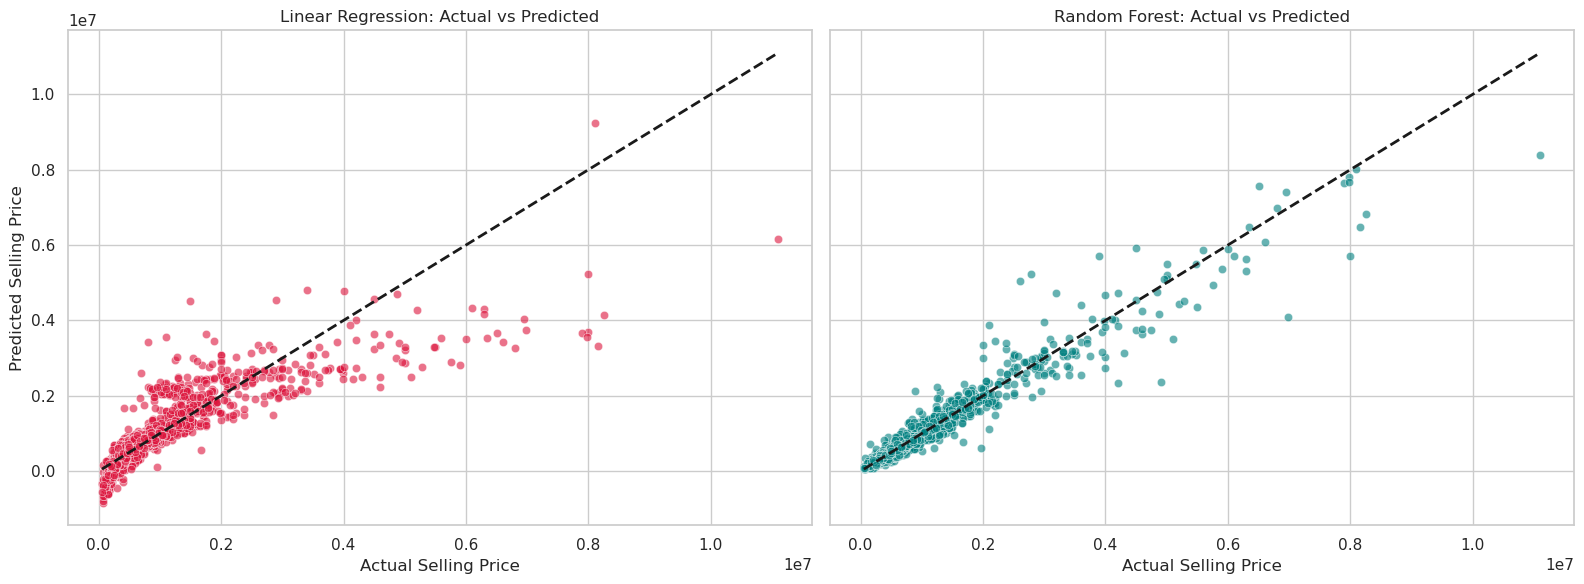

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a side-by-side plotting area
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# 1. Linear Regression Plot
sns.scatterplot(x=y_test, y=lr_pred, ax=axes[0], color='crimson', alpha=0.6)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2) # Perfect prediction line
axes[0].set_title('Linear Regression: Actual vs Predicted')
axes[0].set_xlabel('Actual Selling Price')
axes[0].set_ylabel('Predicted Selling Price')

# 2. Random Forest Plot
sns.scatterplot(x=y_test, y=rf_pred, ax=axes[1], color='teal', alpha=0.6)
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2) # Perfect prediction line
axes[1].set_title('Random Forest: Actual vs Predicted')
axes[1].set_xlabel('Actual Selling Price')

plt.tight_layout()
plt.show()


In [10]:
import pickle

# 1. Save the trained Random Forest model
with open('car_price_model.pkl', 'wb') as model_file:
    pickle.open = pickle.dump(rf_model, model_file)

# 2. CRITICAL: Save the exact list of columns from X
# Because pd.get_dummies creates specific columns, your web app needs to know them!
model_columns = list(X.columns)
with open('model_columns.pkl', 'wb') as columns_file:
    pickle.dump(model_columns, columns_file)

print("Success! Your model and column structures are saved and ready for a web app.")


Success! Your model and column structures are saved and ready for a web app.


In [11]:
import pickle
import pandas as pd

# Load the model back into memory instantly
with open('car_price_model.pkl', 'rb') as model_file:
    loaded_rf_model = pickle.load(model_file)

# Load the required column structure
with open('model_columns.pkl', 'rb') as columns_file:
    saved_columns = pickle.load(columns_file)

print("Model loaded successfully! Ready to take user inputs from a web form.")


Model loaded successfully! Ready to take user inputs from a web form.


In [12]:
# 1. Grab the very first car from your test set clues as our input
sample_input = X_test.iloc[[0]] 

# 2. Make the raw prediction using your newly loaded model (in Rupees)
predicted_rupees = loaded_rf_model.predict(sample_input)[0]

# 3. Convert the Rupee prediction to Nigerian Naira
predicted_naira = predicted_rupees * 18.50

# 4. Get the real actual price from the dataset to compare!
actual_rupees = y_test.iloc[0]
actual_naira = actual_rupees * 18.50

# Print the results side-by-side
print("--- LOADED MODEL VERIFICATION TEST ---")
print(f"Predicted Value: ₹{predicted_rupees:,.2f} INR  |  ₦{predicted_naira:,.2f} NGN")
print(f"Actual Value:    ₹{actual_rupees:,.2f} INR  |  ₦{actual_naira:,.2f} NGN")


--- LOADED MODEL VERIFICATION TEST ---
Predicted Value: ₹636,896.67 INR  |  ₦11,782,588.33 NGN
Actual Value:    ₹625,000.00 INR  |  ₦11,562,500.00 NGN


In [13]:
%%writefile app.py
import streamlit as st
import pandas as pd
import pickle
import numpy as np

# 1. Set up the page title and look
st.set_page_config(page_title="Used Car Price Predictor", page_icon="🚗", layout="centered")

st.title("🚗 Used Car Price Predictor")
st.write("Enter the vehicle specifications below to estimate its market value.")

# 2. Load the trained model and column structure safely
@st.cache_resource  
def load_assets():
    with open('car_price_model.pkl', 'rb') as model_file:
        model = pickle.load(model_file)
    with open('model_columns.pkl', 'rb') as columns_file:
        columns = pickle.load(columns_file)
    return model, columns

try:
    rf_model, saved_columns = load_assets()
except FileNotFoundError:
    st.error("Error: Could not find 'car_price_model.pkl' or 'model_columns.pkl'.")
    st.stop()

# 3. Create the input forms on the web page
st.header("Vehicle Specifications")
col1, col2 = st.columns(2)

with col1:
    year = st.number_input("Year of Manufacture", min_value=1990, max_value=2026, value=2018, step=1)
    km_driven = st.number_input("Kilometers Driven (km)", min_value=0, max_value=1000000, value=50000, step=1000)
    mileage = st.number_input("Fuel Efficiency (km/L)", min_value=0.0, max_value=50.0, value=18.5, step=0.1)
    seats = st.slider("Number of Seats", min_value=2, max_value=10, value=5)

with col2:
    engine = st.number_input("Engine Capacity (CC)", min_value=500, max_value=6000, value=1200, step=100)
    max_power = st.number_input("Max Power (BHP)", min_value=10.0, max_value=500.0, value=85.0, step=1.0)
    fuel_type = st.selectbox("Fuel Type", ["Petrol", "Diesel", "CNG", "LPG"])
    seller_type = st.selectbox("Seller Type", ["Individual", "Dealer", "Trustmark Dealer"])
    transmission_type = st.selectbox("Transmission Type", ["Manual", "Automatic"])

# 4. Processing the prediction
if st.button("Calculate Estimated Value", type="primary"):
    vehicle_age = 2026 - year
    input_data = pd.DataFrame(0, index=[0], columns=saved_columns)
    
    if 'vehicle_age' in input_data.columns: input_data['vehicle_age'] = vehicle_age
    if 'km_driven' in input_data.columns: input_data['km_driven'] = km_driven
    if 'mileage' in input_data.columns: input_data['mileage'] = mileage
    if 'engine' in input_data.columns: input_data['engine'] = engine
    if 'max_power' in input_data.columns: input_data['max_power'] = max_power
    if 'seats' in input_data.columns: input_data['seats'] = seats

    for col in input_data.columns:
        if f"fuel_type_{fuel_type}" in col: input_data[col] = 1
        if f"seller_type_{seller_type}" in col: input_data[col] = 1
        if f"transmission_type_{transmission_type}" in col: input_data[col] = 1

    predicted_rupees = rf_model.predict(input_data)[0]
    predicted_naira = predicted_rupees * 18.50

    st.success("### Valuation Complete!")
    metric_col1, metric_col2 = st.columns(2)
    with metric_col1:
        st.metric(label="Base Value (Kaggle Dataset Currency)", value=f"₹{predicted_rupees:,.2f} INR")
    with metric_col2:
        st.metric(label="Estimated Nigerian Market Value", value=f"₦{predicted_naira:,.2f} NGN")


Overwriting app.py


In [14]:
!pip install streamlit


Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels


In [ ]:
!streamlit run app.py





  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://10.0.0.18:8501
  External URL: http://10.0.0.18:8501



In [3]:
import ipywidgets as widgets
from IPython.display import display, HTML
import pandas as pd
import pickle

# --- ADD THESE 6 LINES TO LOAD YOUR TRAINED MODEL INSTANTLY ---
with open('car_price_model.pkl', 'rb') as model_file:
    rf_model = pickle.load(model_file)

with open('model_columns.pkl', 'rb') as columns_file:
    saved_columns = pickle.load(columns_file)
# -------------------------------------------------------------

# 1. Create the input fields (Sliders and Dropdowns)
style = {'description_width': 'initial'}
year_input = widgets.IntSlider(value=2018, min=1990, max=2026, description="Year:", style=style)
km_input = widgets.IntText(value=50000, description="KM Driven:", style=style)
mileage_input = widgets.FloatText(value=18.5, description="Mileage (km/L):", style=style)
engine_input = widgets.IntText(value=1200, description="Engine (CC):", style=style)
power_input = widgets.FloatText(value=85.0, description="Max Power (BHP):", style=style)
seats_input = widgets.SelectionSlider(options=list(range(2, 11)), value=5, description="Seats:", style=style)

fuel_input = widgets.Dropdown(options=["Petrol", "Diesel", "CNG", "LPG"], value="Petrol", description="Fuel Type:", style=style)
seller_input = widgets.Dropdown(options=["Individual", "Dealer", "Trustmark Dealer"], value="Individual", description="Seller Type:", style=style)
trans_input = widgets.Dropdown(options=["Manual", "Automatic"], value="Manual", description="Transmission:", style=style)

button = widgets.Button(description="Calculate Estimated Value", button_style='success', layout=widgets.Layout(width='50%'))
output = widgets.Output()

# 2. Prediction handler
def on_button_clicked(b):
    with output:
        output.clear_output()
        vehicle_age = 2026 - year_input.value
        input_data = pd.DataFrame(0, index=[0], columns=saved_columns)
        
        if 'vehicle_age' in input_data.columns: input_data['vehicle_age'] = vehicle_age
        if 'km_driven' in input_data.columns: input_data['km_driven'] = km_input.value
        if 'mileage' in input_data.columns: input_data['mileage'] = mileage_input.value
        if 'engine' in input_data.columns: input_data['engine'] = engine_input.value
        if 'max_power' in input_data.columns: input_data['max_power'] = power_input.value
        if 'seats' in input_data.columns: input_data['seats'] = seats_input.value

        for col in input_data.columns:
            if f"fuel_type_{fuel_input.value}" in col: input_data[col] = 1
            if f"seller_type_{seller_input.value}" in col: input_data[col] = 1
            if f"transmission_type_{trans_input.value}" in col: input_data[col] = 1

        pred_rupees = rf_model.predict(input_data)[0]
        pred_naira = pred_rupees * 18.50
        
        display(HTML(f"""
        <div style="padding:15px; background-color:#e1f5fe; border-radius:5px; border-left: 5px solid #0288d1; margin-top:10px;">
            <h4 style="margin:0; color:#01579b;">🚗 Valuation Complete!</h4>
            <p style="margin:5px 0 0 0; font-size:16px;"><b>Estimated Market Value (INR):</b> ₹{pred_rupees:,.2f}</p>
            <p style="margin:5px 0 0 0; font-size:18px; color:#2e7d32;"><b>Estimated Nigerian Market Value (NGN):</b> ₦{pred_naira:,.2f}</p>
        </div>
        """))

button.on_click(on_button_clicked)

# 3. Render Dashboard Layout
st_ui = widgets.VBox([
    widgets.HTML("<h2>🚗 Used Car Price Predictor Dashboard</h2>"),
    widgets.TwoByTwoLayout(top_left=year_input, top_right=engine_input, bottom_left=km_input, bottom_right=power_input),
    widgets.TwoByTwoLayout(top_left=mileage_input, top_right=fuel_input, bottom_left=seats_input, bottom_right=seller_input),
    widgets.HBox([trans_input]), widgets.HTML("<br>"), button, output
])
display(st_ui)
